## **Cross Dataset Test**

In [2]:
import warnings
warnings.filterwarnings('ignore')

In [3]:
%load_ext autoreload
%autoreload 3

In [4]:
# Import all python library packages
from lib_imports import *

In [8]:
print("=" * 50)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("CUDA version:", torch.version.cuda)
    print("CUDA device count:", torch.cuda.device_count())
    print("Current GPU:", torch.cuda.get_device_name(0))
    print("cuDNN version:", torch.backends.cudnn.version())
print()
print("ONNXRuntime version:", ort.__version__)
print("ONNX providers:", ort.get_available_providers())
print("=" * 50)

# Automatic device detection
RUNTIME_MODE = "auto"        # Options: "auto", "cpu", "gpu", "mps"

# auto — pick the best available device
if torch.cuda.is_available():
    DEVICE = torch.device("cuda")                 # NVIDIA GPU
elif torch.backends.mps.is_available():
    DEVICE = torch.device("mps")                  # Apple Silicon GPU
else:
    DEVICE = torch.device("cpu")                  # Fallback to CPU

# Print device name
print("Using device:", DEVICE)
if DEVICE.type == "cuda":
    print("Device name:", torch.cuda.get_device_name(0))
elif DEVICE.type == "mps":
    print("Device name: Apple Silicon GPU (MPS)")
else:
    print("Device name: CPU")

PyTorch version: 2.5.1+cu121
CUDA available: True
CUDA version: 12.1
CUDA device count: 1
Current GPU: NVIDIA L40S
cuDNN version: 90100

ONNXRuntime version: 1.26.0
ONNX providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']
Using device: cuda
Device name: NVIDIA L40S


<div style="background-color: #FFB6C1; padding: 12px; border-radius: 6px;">
    <h2 style="margin: 0;">Case 1 – Train on OULU P1's Train+Dev <-> Test on SiW P1's Test</h2>
</div>

<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

In [14]:
# Path for OULU-NPU P1's best model checkpoints
BEST_CKPT_OULU_P1 = Path('./output_OULU-NPU/results/protocol_1/best_model_protocol_1.pth')

In [16]:
from Functions.full_model_pipeline_13 import *

# Build the model and load OULU's trained weights into it
model = HybridPADModel().to(DEVICE)

ckpt = torch.load(BEST_CKPT_OULU_P1, map_location=DEVICE, weights_only=False)
model.load_state_dict(ckpt['state_dict'])

print(f"Loaded OULU P1 checkpoint (epoch {ckpt['epoch']}, dev ACER={ckpt['dev_acer']:.4f})")

Loaded OULU P1 checkpoint (epoch 8, dev ACER=0.0167)


In [18]:
from Functions.loss_functions_14 import *

# Step 3 — criterion + dummy optimizer (required by run_epoch's signature, not actually used to train)
criterion = CompoundFASLoss()
optimizer = optim.AdamW(model.parameters(), lr=CFG.LR)

model.eval();   # safety net — ensures dropout/batchnorm behave correctly even if run_epoch doesn't set this itself

In [20]:
# Configurations for SiW

# Paths (where data and outputs are stored)
DATA_ROOT_SiW   = Path('./DATA/SiW-Mv2')                                                           # Main dataset folder
REAL_DIR_SiW    = DATA_ROOT_SiW / 'Live'                                                           # Folder for real videos
ATTACK_DIRS_SiW = {                                                                                # Attack folders collected in a set
    'makeup_cosmetic'         :   DATA_ROOT_SiW / 'Spoof' / 'Makeup_Cosmetic',
    'makeup_impersonation'    :   DATA_ROOT_SiW / 'Spoof' / 'Makeup_Impersonation',
    'makeup_obfuscation'      :   DATA_ROOT_SiW / 'Spoof' / 'Makeup_Obfuscation',
    'mannequin'               :   DATA_ROOT_SiW / 'Spoof' / 'Mannequin',
    'mask_halfmask'           :   DATA_ROOT_SiW / 'Spoof' / 'Mask_HalfMask',
    'mask_papermask'          :   DATA_ROOT_SiW / 'Spoof' / 'Mask_PaperMask',
    'mask_transparentmask'    :   DATA_ROOT_SiW / 'Spoof' / 'Mask_TransparentMask',
    'paper'                   :   DATA_ROOT_SiW / 'Spoof' / 'Paper',
    'partial_eye'             :   DATA_ROOT_SiW / 'Spoof' / 'Partial_Eye',
    'partial_funnyeyeglasses' :   DATA_ROOT_SiW / 'Spoof' / 'Partial_FunnyeyeGlasses',
    'partial_mouth'           :   DATA_ROOT_SiW / 'Spoof' / 'Partial_Mouth',
    'partial_paperglasses'    :   DATA_ROOT_SiW / 'Spoof' / 'Partial_PaperGlasses',
    'replay'                  :   DATA_ROOT_SiW / 'Spoof' / 'Replay',
    'silicone'                :   DATA_ROOT_SiW / 'Spoof' / 'Silicone'       
}   


PROTOCOL_DIR_SiW = DATA_ROOT_SiW / 'subjects_split_info'

OUTPUT_ROOT_SiW = Path('./output_siW')                                                           # Main output folder
CACHE_DIR_SiW   = OUTPUT_ROOT_SiW / 'frame_cache'                                                # Store extracted frames
RESULT_DIR_SiW  = OUTPUT_ROOT_SiW / 'results'

TEST_DIR_SiW = Path('./test_siW_files')                                                          # Store testing files like checking landmarks etc midway

# Used by Protocol 2 (leave-one-attack-out). 'live' is the bona-fide class.
SPOOF_ATTACKS_SiW = list(ATTACK_DIRS_SiW.keys())
REAL_LABEL_SiW = 'live'   # the bona-fide / real class name


# PROTOCOL-SPECIFIC CONFIG
PROTOCOL_CONFIG_SiW = {
    # ---- Protocol I: Known Spoof Attack Detection -------------------
    1 : {
        'mode'             : 'known',
        'train_live_P1'    : PROTOCOL_DIR_SiW / 'trainlist_live.txt',
        'train_spoof_P1'   : PROTOCOL_DIR_SiW / 'trainlist_all.txt',
        'test_live_P1'     : PROTOCOL_DIR_SiW / 'testlist_live.txt',
        'test_spoof_P1'    : PROTOCOL_DIR_SiW / 'testlist_all.txt',
        'ckpt'             : RESULT_DIR_SiW / 'protocol_1' / 'best_model_protocol_1.pth',
        'result'           : RESULT_DIR_SiW / 'protocol_1',
    },
 
    # ---- Protocol II: Unknown Spoof Attack Detection ---------------
    2 : {
        'mode'                     : 'leave_one_attack_out',
        'train_live_P2_80per'      : PROTOCOL_DIR_SiW / 'trainlist_live.txt',
        'test_live_P2_20per'       : PROTOCOL_DIR_SiW / 'testlist_live.txt',
        'live_train_frac'          : 0.80,                                        # 80-20 split of live samples
        'ckpt_prefix'              : RESULT_DIR_SiW / 'protocol_2' / 'best_model_protocol_2_',     # + <attack>.pth
        'result'                   : RESULT_DIR_SiW / 'protocol_2',
    },
 
    # ---- Protocol III: Cross-domain Spoof Detection ----------------
    3 : {
        'mode'                        : 'cross_domain',
        'train_source_domain_A_P3'    : PROTOCOL_DIR_SiW / 'train_A_pretrain.txt',    # source domain for training
        'test_spoof_domain_B_P3'      : PROTOCOL_DIR_SiW / 'test_B_spoof.txt',        # target domain B subject for testing
        'test_race_domain_C_P3'       : PROTOCOL_DIR_SiW / 'test_C_race.txt',         # target domain C subject for testing
        'test_age_domain_D_P3'        : PROTOCOL_DIR_SiW / 'test_D_age.txt',          # target domain D subject for testing
        'test_illu_domain_E_P3'       : PROTOCOL_DIR_SiW / 'test_E_ill.txt',         # target domain E subject for testing
        'n_domains'                   : 5,
        'ckpt_prefix'                 : RESULT_DIR_SiW / 'protocol_3' / 'best_model_protocol_3_',  # + <domain>.pth
        'result'                      : RESULT_DIR_SiW / 'protocol_3',
    }
}

print("Data Root:", DATA_ROOT_SiW)
print("Real:", REAL_DIR_SiW)
print("Attack:", ATTACK_DIRS_SiW)
print("Protocol:", PROTOCOL_DIR_SiW)
print("Cache:", CACHE_DIR_SiW)
print("Results (All):", RESULT_DIR_SiW)


Data Root: DATA/SiW-Mv2
Real: DATA/SiW-Mv2/Live
Attack: {'makeup_cosmetic': PosixPath('DATA/SiW-Mv2/Spoof/Makeup_Cosmetic'), 'makeup_impersonation': PosixPath('DATA/SiW-Mv2/Spoof/Makeup_Impersonation'), 'makeup_obfuscation': PosixPath('DATA/SiW-Mv2/Spoof/Makeup_Obfuscation'), 'mannequin': PosixPath('DATA/SiW-Mv2/Spoof/Mannequin'), 'mask_halfmask': PosixPath('DATA/SiW-Mv2/Spoof/Mask_HalfMask'), 'mask_papermask': PosixPath('DATA/SiW-Mv2/Spoof/Mask_PaperMask'), 'mask_transparentmask': PosixPath('DATA/SiW-Mv2/Spoof/Mask_TransparentMask'), 'paper': PosixPath('DATA/SiW-Mv2/Spoof/Paper'), 'partial_eye': PosixPath('DATA/SiW-Mv2/Spoof/Partial_Eye'), 'partial_funnyeyeglasses': PosixPath('DATA/SiW-Mv2/Spoof/Partial_FunnyeyeGlasses'), 'partial_mouth': PosixPath('DATA/SiW-Mv2/Spoof/Partial_Mouth'), 'partial_paperglasses': PosixPath('DATA/SiW-Mv2/Spoof/Partial_PaperGlasses'), 'replay': PosixPath('DATA/SiW-Mv2/Spoof/Replay'), 'silicone': PosixPath('DATA/SiW-Mv2/Spoof/Silicone')}
Protocol: DATA/SiW-Mv

In [21]:
# Next step:
# Build SiW-Mv2's Protocol I test set: 
#  -read the partition files, 
#  -filter SiW dataframe down to just those videos, 
#  -then wrap it in a Dataset/DataLoader.

# ============================================================================
#  Step a — build df_SiW (SiW-Mv2 dataframe: path, label, attack_type,
#  filename, subject_id, duration)
# ============================================================================

VIDEO_EXTS = {'.mp4', '.avi', '.mov', '.mkv', '.webm'}
checkpoint_files = []   # any checkpoint files found on disk, excluded from df_SiW

def collect_videos_from_dir(root_dir, label, attack_type):
    records = []
    for p in root_dir.rglob('*'):
        if p.suffix.lower() not in VIDEO_EXTS:
            continue
        if 'checkpoint' in str(p).lower():
            checkpoint_files.append(str(p))
            continue
        records.append({'path': str(p), 'label': label, 'attack_type': attack_type,
                         'filename': p.name, 'subject_id': p.stem})
    return records

# ---- collect real + all attack-type videos ----
missing = [str(d) for d in [REAL_DIR_SiW, *ATTACK_DIRS_SiW.values()] if not d.exists()]
if missing:
    raise FileNotFoundError(f"SiW folders not found (check paths before continuing): {missing}")

records = collect_videos_from_dir(REAL_DIR_SiW, label=0, attack_type='real')
for attack_type, attack_dir in ATTACK_DIRS_SiW.items():
    recs = collect_videos_from_dir(attack_dir, label=1, attack_type=attack_type)
    records.extend(recs)
    print(f'  {attack_type:<12}: {len(recs):,} videos')

df_SiW = pd.DataFrame(records)

# ---- duration column (seconds), one helper applied per row ----
def _get_duration(path):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        return 0
    fps, n_frames = cap.get(cv2.CAP_PROP_FPS), cap.get(cv2.CAP_PROP_FRAME_COUNT)
    cap.release()
    return n_frames / fps if fps > 0 else 0

df_SiW['duration'] = df_SiW['path'].apply(_get_duration)

# ---- report ----
print(f'\nTotal: {len(df_SiW):,} videos '
      f'({(df_SiW.label==0).sum():,} real | {(df_SiW.label==1).sum():,} fake)')
print(df_SiW.groupby(['label', 'attack_type']).size().to_string())
if checkpoint_files:
    print(f'\nExcluded {len(checkpoint_files)} checkpoint file(s) from df_SiW.')

  makeup_cosmetic: 52 videos
  makeup_impersonation: 61 videos
  makeup_obfuscation: 22 videos
  mannequin   : 40 videos
  mask_halfmask: 72 videos
  mask_papermask: 17 videos
  mask_transparentmask: 60 videos
  paper       : 135 videos
  partial_eye : 57 videos
  partial_funnyeyeglasses: 179 videos
  partial_mouth: 29 videos
  partial_paperglasses: 76 videos
  replay      : 98 videos
  silicone    : 17 videos

Total: 1,700 videos (785 real | 915 fake)
label  attack_type            
0      real                       785
1      makeup_cosmetic             52
       makeup_impersonation        61
       makeup_obfuscation          22
       mannequin                   40
       mask_halfmask               72
       mask_papermask              17
       mask_transparentmask        60
       paper                      135
       partial_eye                 57
       partial_funnyeyeglasses    179
       partial_mouth               29
       partial_paperglasses        76
       replay     

In [22]:
df_SiW.head()

,path,label,attack_type,filename,subject_id,duration
0,DATA/SiW-Mv2/Live/Live_1.mov,0,real,Live_1.mov,Live_1,10.0
1,DATA/SiW-Mv2/Live/Live_10.mov,0,real,Live_10.mov,Live_10,10.0
2,DATA/SiW-Mv2/Live/Live_100.mov,0,real,Live_100.mov,Live_100,10.0
3,DATA/SiW-Mv2/Live/Live_101.mov,0,real,Live_101.mov,Live_101,10.0
4,DATA/SiW-Mv2/Live/Live_102.mov,0,real,Live_102.mov,Live_102,10.0


In [27]:
# ============================================================================
#  Step b — build SiW-Mv2's Protocol I TEST set (target domain, unseen)
# ============================================================================
from Functions.data_pipeline_setup_7 import *
from Functions.augmentations_6 import *

def _read_ids(p):
    with open(p) as f:
        return set(line.strip() for line in f if line.strip())

pcfg_siw1 = PROTOCOL_CONFIG_SiW[1]
siw_test_live_ids  = _read_ids(pcfg_siw1['test_live_P1'])
siw_test_spoof_ids = _read_ids(pcfg_siw1['test_spoof_P1'])

df_siw_ids = set(df_SiW['subject_id'])
siw_test_df = df_SiW[df_SiW['subject_id'].isin((siw_test_live_ids | siw_test_spoof_ids) & df_siw_ids)].copy()

print(f"SiW-Mv2 P1 test set: {len(siw_test_df)} videos "
      f"(real {(siw_test_df['label']==0).sum()}, fake {(siw_test_df['label']==1).sum()})")

# Create augmentation pipelines
train_transforms = get_transforms('train')  # training pipeline with augmentations
val_transforms   = get_transforms('val')    # validation pipeline without randomness


siw_test_dataset = PADVideoDataset(siw_test_df, real_dir=REAL_DIR_SiW, cache_dir=CACHE_DIR_SiW,
                                   transform=val_transforms, demo_mode=False,
                                   use_freq=CFG.USE_FREQ_STREAM, use_flow=CFG.USE_FLOW_STREAM)
siw_test_loader = DataLoader(siw_test_dataset, batch_size=CFG.BATCH_SIZE, shuffle=False,
                             num_workers=2, pin_memory=True, prefetch_factor=2, persistent_workers=True)

SiW-Mv2 P1 test set: 623 videos (real 261, fake 362)


In [29]:
# Configuration of OULU

# Paths (where data and outputs are stored)
DATA_ROOT_OULU   = Path('./DATA/OULU-NPU')                                                         # Main dataset folder
REAL_DIR_OULU    = DATA_ROOT_OULU / 'useful_splits' / 'real'                                       # Folder for real videos
ATTACK_DIRS_OULU = {                                                                               # Attack folders collected in a set
    'presentation'         :   DATA_ROOT_OULU / 'useful_splits' / 'presentation',
    'replay'               :   DATA_ROOT_OULU / 'useful_splits' / 'replay',      
}   
PROTOCOL_DIR_OULU = DATA_ROOT_OULU / 'Protocols'

OUTPUT_ROOT_OULU = Path('./output_OULU-NPU')                                                       # Main output folder
CACHE_DIR_OULU   = OUTPUT_ROOT_OULU / 'frame_cache'                                                # Store extracted frames
RESULT_DIR_OULU  = OUTPUT_ROOT_OULU / 'results'

TEST_DIR_OULU = Path('./test_output_OULU-NPU_files')                                               # Store testing files like checking landmarks etc midway

# Used by Protocol 3,4 (leave-one-attack-out). 'live' is the bona-fide class.
SPOOF_ATTACKS_OULU = list(ATTACK_DIRS_OULU.keys())
REAL_LABEL_OULU = 'live'   # the bona-fide / real class name


# PROTOCOL-SPECIFIC CONFIG
PROTOCOL_CONFIG_OULU = {

    # ---- Protocol I: Unseen environment -------------------
    1 : {
        'mode'             : 'unseen_environment',
        'train_P1'         : PROTOCOL_DIR_OULU / 'Protocol_1' / 'Train.txt',
        'dev_P1'           : PROTOCOL_DIR_OULU / 'Protocol_1' / 'Dev.txt',
        'test_P1'          : PROTOCOL_DIR_OULU / 'Protocol_1' / 'Test.txt',
        'ckpt'             : RESULT_DIR_OULU / 'protocol_1' / 'best_model_protocol_1.pth',
        'result'           : RESULT_DIR_OULU / 'protocol_1'
    },
    
    # ---- Protocol II: Unseen attack ---------------
    2 : {
        'mode'                     : 'unseen_attack',
        'train_P2'                 : PROTOCOL_DIR_OULU / 'Protocol_2' / 'Train.txt',
        'dev_P2'                   : PROTOCOL_DIR_OULU / 'Protocol_2' / 'Dev.txt',
        'test_P2'                  : PROTOCOL_DIR_OULU / 'Protocol_2' / 'Test.txt',
        'ckpt'                     : RESULT_DIR_OULU / 'protocol_2' / 'best_model_protocol_2.pth',
        'result'                   : RESULT_DIR_OULU / 'protocol_2'
    },
    
        
    # ---- Protocol III: Leave One Camera Out (LOCO) ---------------
    3 : {
        'mode'                     : 'leave_one_camera_out',
        'train_P3'                 : [PROTOCOL_DIR_OULU / 'Protocol_3' / f'Train_{i}.txt' for i in range(1, 7)],
        'dev_P3'                   : [PROTOCOL_DIR_OULU / 'Protocol_3' / f'Dev_{i}.txt'   for i in range(1, 7)],
        'test_P3'                  : [PROTOCOL_DIR_OULU / 'Protocol_3' / f'Test_{i}.txt'  for i in range(1, 7)],    
        'ckpt_prefix'              : RESULT_DIR_OULU / 'protocol_3' / 'best_model_protocol_3_',     # + <fold>.pth  e.g. fold1.pth
        'result'                   : RESULT_DIR_OULU / 'protocol_3'
    },

    
    # ---- Protocol IV: All unseen ----------------
    4 : {
        'mode'                     : 'all_unseen',
        'train_P4'                 : [PROTOCOL_DIR_OULU / 'Protocol_4' / f'Train_{i}.txt' for i in range(1, 7)],
        'dev_P4'                   : [PROTOCOL_DIR_OULU / 'Protocol_4' / f'Dev_{i}.txt'   for i in range(1, 7)],
        'test_P4'                  : [PROTOCOL_DIR_OULU / 'Protocol_4' / f'Test_{i}.txt'  for i in range(1, 7)],    
        'ckpt_prefix'              : RESULT_DIR_OULU / 'protocol_4' / 'best_model_protocol_4_',     # + <fold>.pth  e.g. fold1.pth
        'result'                   : RESULT_DIR_OULU / 'protocol_4'
    },
}

print("Data Root:", DATA_ROOT_OULU)
print("Real:", REAL_DIR_OULU)
print("Attack:", ATTACK_DIRS_OULU)
print("Protocol:", PROTOCOL_DIR_OULU)
print("Cache:", CACHE_DIR_OULU)
print("Results (All):", RESULT_DIR_OULU)

Data Root: DATA/OULU-NPU
Real: DATA/OULU-NPU/useful_splits/real
Attack: {'presentation': PosixPath('DATA/OULU-NPU/useful_splits/presentation'), 'replay': PosixPath('DATA/OULU-NPU/useful_splits/replay')}
Protocol: DATA/OULU-NPU/Protocols
Cache: output_OULU-NPU/frame_cache
Results (All): output_OULU-NPU/results


In [30]:
# ============================================================================
#  Build df_oulu (OULU dataframe, same structure as df_SiW)
# ============================================================================
missing_oulu = [str(d) for d in [REAL_DIR_OULU, *ATTACK_DIRS_OULU.values()] if not d.exists()]
if missing_oulu:
    raise FileNotFoundError(f"OULU folders not found: {missing_oulu}")

records_oulu = collect_videos_from_dir(REAL_DIR_OULU, label=0, attack_type='real')
for attack_type, attack_dir in ATTACK_DIRS_OULU.items():
    recs = collect_videos_from_dir(attack_dir, label=1, attack_type=attack_type)
    records_oulu.extend(recs)
    print(f'  {attack_type:<12}: {len(recs):,} videos')

df_oulu = pd.DataFrame(records_oulu)
df_oulu['duration'] = df_oulu['path'].apply(_get_duration)

print(f'\nTotal: {len(df_oulu):,} videos '
      f'({(df_oulu.label==0).sum():,} real | {(df_oulu.label==1).sum():,} fake)')

  presentation: 3,208 videos
  replay      : 688 videos

Total: 4,871 videos (975 real | 3,896 fake)


In [32]:
df_oulu.head()

,path,label,attack_type,filename,subject_id,duration
0,DATA/OULU-NPU/useful_splits/real/1_1_21_1.avi,0,real,1_1_21_1.avi,1_1_21_1,5.031396
1,DATA/OULU-NPU/useful_splits/real/1_1_22_1.avi,0,real,1_1_22_1.avi,1_1_22_1,5.031380
2,DATA/OULU-NPU/useful_splits/real/1_1_23_1.avi,0,real,1_1_23_1.avi,1_1_23_1,5.031350
3,DATA/OULU-NPU/useful_splits/real/1_1_24_1.avi,0,real,1_1_24_1.avi,1_1_24_1,5.031350
4,DATA/OULU-NPU/useful_splits/real/1_1_25_1.avi,0,real,1_1_25_1.avi,1_1_25_1,5.031380


In [35]:
# ============================================================================
#  Build OULU's Protocol I DEV set (source domain) and tune threshold
# ============================================================================
from Functions.run_epochs_17 import *

def _read_ids_oulu(p):
    # OULU-NPU partition files are "label,video_name" per line, e.g. "+1,4_1_11_4"
    # — one combined file per split (not separate live/spoof files like SiW)
    ids = set()
    with open(p) as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            name = line.split(',')[1].strip() if ',' in line else line
            ids.add(name)
    return ids

pc_oulu1 = PROTOCOL_CONFIG_OULU[1]
oulu_dev_ids = _read_ids_oulu(pc_oulu1['dev_P1'])   # <- fixed: single 'dev_P1' file, not separate live/spoof keys

oulu_dev_df = df_oulu[df_oulu['subject_id'].isin(oulu_dev_ids)].copy()

print(f"OULU P1 dev set: {len(oulu_dev_df)} videos "
      f"(real {(oulu_dev_df['label']==0).sum()}, fake {(oulu_dev_df['label']==1).sum()})")
if len(oulu_dev_df) == 0:
    print("  !! WARNING: 0 matched — check df_oulu['subject_id'] format vs oulu_dev_ids")
    print("     Example df_oulu stems:", df_oulu['subject_id'].head(3).tolist())
    print("     Example file ids     :", list(oulu_dev_ids)[:3])

oulu_dev_dataset = PADVideoDataset(oulu_dev_df, real_dir=REAL_DIR_OULU, cache_dir=CACHE_DIR_OULU,
                                   transform=val_transforms, demo_mode=False,
                                   use_freq=CFG.USE_FREQ_STREAM, use_flow=CFG.USE_FLOW_STREAM)
dev_loader_P1 = DataLoader(oulu_dev_dataset, batch_size=CFG.BATCH_SIZE, shuffle=False,
                           num_workers=2, pin_memory=True, prefetch_factor=2, persistent_workers=True)

# ---- run one eval pass over OULU's dev set, find the ACER-minimizing threshold ----
_, _, dev_probs, dev_labels, _, _ = run_epoch(
    model, dev_loader_P1, optimizer, criterion, DEVICE, scaler=None, is_train=False)
dev_labels_int = dev_labels.round().astype(int)
thresholds = np.linspace(0.1, 0.9, 100)
dev_acers = [compute_pad_metrics(dev_labels_int, dev_probs, t)['ACER'] for t in thresholds]
best_thresh = thresholds[np.argmin(dev_acers)]

print(f"Threshold tuned on OULU P1 dev (source domain): {best_thresh:.3f}")

OULU P1 dev set: 900 videos (real 180, fake 720)


Threshold tuned on OULU P1 dev (source domain): 0.464


In [36]:
# ============================================================================
#  Evaluate on SiW's test set, compute ALL metrics, save
# ============================================================================
test_loss, test_metrics, test_probs, test_labels, _, test_attacks = run_epoch(
    model, siw_test_loader, optimizer, criterion, DEVICE, scaler=None, is_train=False)
test_labels_int = test_labels.round().astype(int)
opt_metrics = compute_pad_metrics(test_labels_int, test_probs, threshold=best_thresh)
tdr = compute_tdr_at_fdr(test_labels_int, test_probs, target_fdr=0.01)

hter = (opt_metrics['APCER'] + opt_metrics['BPCER']) / 2   # standard cross-dataset metric

print(f'\nOptimal Threshold (from OULU dev) = {best_thresh:.3f}')
print('=' * 50)
print('CROSS-DATASET: OULU (train) -> SiW-Mv2 (test), Protocol I')
print('-' * 50)
print(f'  HTER    : {hter*100:.2f}%  (lower=better)')
for k, v in opt_metrics.items():
    direction = 'lower=better' if k in ['APCER', 'BPCER', 'ACER'] else 'higher=better'
    print(f'  {k:8s}: {v*100:.2f}%  ({direction})')
print(f'  TDR@1%  : {tdr*100:.2f}%  (higher=better)')

# ---- Save — a standalone location, NOT inside OULU's result folder ----
CROSS_DATASET_RESULT_DIR = Path('./output_crossData/TrainOULUP1_TestSiWP1')   # <- cross Data results path
CROSS_DATASET_RESULT_DIR.mkdir(parents=True, exist_ok=True)

results_to_save = {
    'direction': 'OULU->SiW-Mv2 (Protocol I)',
    'best_threshold': float(best_thresh),
    'HTER': float(hter),
    'test_metrics': {**{k: float(v) for k, v in opt_metrics.items()}, 'TDR': float(tdr)},
    'checkpoint_epoch': int(ckpt['epoch']),
    'n_test_videos': int(len(siw_test_df)),
    'n_test_real': int((siw_test_df['label']==0).sum()),
    'n_test_fake': int((siw_test_df['label']==1).sum()),
}
with open(CROSS_DATASET_RESULT_DIR / 'oulu_to_siw_p1_test_metrics.json', 'w') as f:
    json.dump(results_to_save, f, indent=2)

print(f'\nResults saved to {CROSS_DATASET_RESULT_DIR / "oulu_to_siw_p1_test_metrics.json"}')


Optimal Threshold (from OULU dev) = 0.464
CROSS-DATASET: OULU (train) -> SiW-Mv2 (test), Protocol I
--------------------------------------------------
  HTER    : 37.09%  (lower=better)
  APCER   : 37.02%  (lower=better)
  BPCER   : 37.16%  (lower=better)
  ACER    : 37.09%  (lower=better)
  Acc     : 62.92%  (higher=better)
  AUC     : 67.36%  (higher=better)
  TDR@1%  : 414.36%  (higher=better)

Results saved to output_crossData/TrainOULUP1_TestSiWP1/oulu_to_siw_p1_test_metrics.json


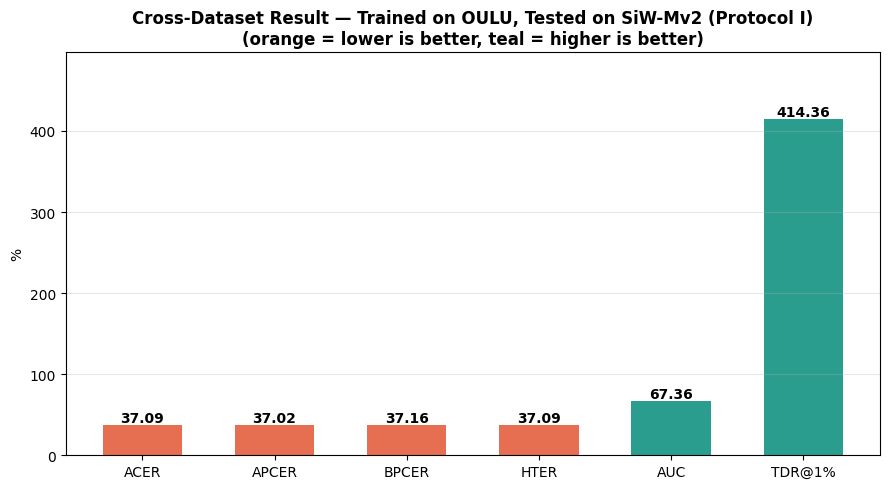

Chart saved to output_crossData/TrainOULUP1_TestSiWP1/oulu_to_siw_p1_barchart.png


In [37]:
# ============================================================================
#  Bar chart: OULU -> SiW-Mv2 cross-dataset result (all metrics)
# ============================================================================

metric_names = ['ACER', 'APCER', 'BPCER', 'HTER', 'AUC', 'TDR@1%']
metric_values = [
    opt_metrics['ACER'] * 100,
    opt_metrics['APCER'] * 100,
    opt_metrics['BPCER'] * 100,
    hter * 100,
    opt_metrics['AUC'] * 100,
    tdr,
]
# lower=better metrics get one color, higher=better metrics get another
colors = ['#e76f51' if m in ['ACER', 'APCER', 'BPCER', 'HTER'] else '#2a9d8f' for m in metric_names]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(metric_names, metric_values, color=colors, width=0.6)

# value labels on top of each bar
for b in bars:
    ax.text(b.get_x() + b.get_width()/2, b.get_height(), f'{b.get_height():.2f}',
            ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_title('Cross-Dataset Result — Trained on OULU, Tested on SiW-Mv2 (Protocol I)\n'
             '(orange = lower is better, teal = higher is better)', fontweight='bold')
ax.set_ylabel('%')
ax.set_ylim(0, max(metric_values) * 1.2)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()

chart_path = CROSS_DATASET_RESULT_DIR / 'oulu_to_siw_p1_barchart.png'
plt.savefig(chart_path, dpi=120, bbox_inches='tight')
plt.show()

print(f'Chart saved to {chart_path}')

<div style="background-color: #FFF9C4; padding: 12px; border-radius: 6px;">
<hr style="border: none; height: 3px; background-color: #FFD600;">
</div>

<div style="background-color: #FFB6C1; padding: 12px; border-radius: 6px;">
    <h2 style="margin: 0;">Case 2 – Train on SiW P1's Train+Dev <-> Test on OULU P1's Test</h2>
</div>

In [38]:
# ============================================================================
#  CROSS-DATASET EVAL — Direction 2: Train on SiW-Mv2 (P1), Test on OULU (P1)
# ----------------------------------------------------------------------------
#  Mirrors Direction 1 exactly, reversed. Reuses df_SiW and df_oulu already
#  built for Direction 1 — no need to rebuild them.
#
#  KEY DIFFERENCE from Direction 1's threshold-tuning step: SiW's P1 config
#  has NO separate dev/val file (only 'train_live_P1'/'train_spoof_P1'/
#  'test_live_P1'/'test_spoof_P1') — unlike OULU, which has a dedicated
#  'dev_P1' file. So here the val set is CARVED out of SiW's train set via
#  GroupShuffleSplit (same approach used in your P2/P3 SiW training scripts),
#  not read from a fixed file.
# ============================================================================

# ---- Step 1-2: load the SiW P1 checkpoint ----
BEST_CKPT_SIW_P1 = PROTOCOL_CONFIG_SiW[1]['ckpt']   # RESULT_DIR_SiW / 'protocol_1' / 'best_model_protocol_1.pth'

model2 = HybridPADModel().to(DEVICE)
ckpt2 = torch.load(BEST_CKPT_SIW_P1, map_location=DEVICE, weights_only=False)
model2.load_state_dict(ckpt2['state_dict'])
print(f"Loaded SiW P1 checkpoint (epoch {ckpt2['epoch']}, val ACER={ckpt2.get('val_acer', ckpt2.get('dev_acer', '?'))})")

# ---- Step 3: criterion + dummy optimizer, eval mode ----
criterion2 = CompoundFASLoss()
optimizer2 = optim.AdamW(model2.parameters(), lr=CFG.LR)
model2.eval();

# ---- Step 4: carve SiW's train set into Train/Val (val used for threshold tuning) ----
pcfg_siw1 = PROTOCOL_CONFIG_SiW[1]
siw_train_live_ids  = _read_ids(pcfg_siw1['train_live_P1'])
siw_train_spoof_ids = _read_ids(pcfg_siw1['train_spoof_P1'])

df_siw_ids = set(df_SiW['subject_id'])
siw_train_full_df = df_SiW[df_SiW['subject_id'].isin((siw_train_live_ids | siw_train_spoof_ids) & df_siw_ids)].copy()

gss2 = GroupShuffleSplit(n_splits=1, test_size=CFG.VAL_RATIO, random_state=SEED)
tr_idx2, val_idx2 = next(gss2.split(siw_train_full_df, groups=siw_train_full_df['subject_id']))
siw_val_df = siw_train_full_df.iloc[val_idx2].copy()   # only the val slice is needed here — train slice unused for eval-only

print(f"SiW P1 val set (carved from train): {len(siw_val_df)} videos "
      f"(real {(siw_val_df['label']==0).sum()}, fake {(siw_val_df['label']==1).sum()})")

siw_val_dataset = PADVideoDataset(siw_val_df, real_dir=REAL_DIR_SiW, cache_dir=CACHE_DIR_SiW,
                                  transform=val_transforms, demo_mode=False,
                                  use_freq=CFG.USE_FREQ_STREAM, use_flow=CFG.USE_FLOW_STREAM)
siw_val_loader = DataLoader(siw_val_dataset, batch_size=CFG.BATCH_SIZE, shuffle=False,
                            num_workers=2, pin_memory=True, prefetch_factor=2, persistent_workers=True)

# ---- Step 5: tune threshold on SiW's own val set (source domain) ----
_, _, siw_val_probs, siw_val_labels, _, _ = run_epoch(
    model2, siw_val_loader, optimizer2, criterion2, DEVICE, scaler=None, is_train=False)
siw_val_labels_int = siw_val_labels.round().astype(int)
thresholds2 = np.linspace(0.1, 0.9, 100)
siw_val_acers = [compute_pad_metrics(siw_val_labels_int, siw_val_probs, t)['ACER'] for t in thresholds2]
best_thresh2 = thresholds2[np.argmin(siw_val_acers)]
print(f"Threshold tuned on SiW P1 val (source domain): {best_thresh2:.3f}")

# ---- Step 6: build OULU's P1 TEST set (target domain, using its combined-file format) ----
pc_oulu1 = PROTOCOL_CONFIG_OULU[1]
oulu_test_ids = _read_ids_oulu(pc_oulu1['test_P1'])   # single combined file, "label,name" per line

oulu_test_df = df_oulu[df_oulu['subject_id'].isin(oulu_test_ids)].copy()
print(f"OULU P1 test set: {len(oulu_test_df)} videos "
      f"(real {(oulu_test_df['label']==0).sum()}, fake {(oulu_test_df['label']==1).sum()})")

oulu_test_dataset = PADVideoDataset(oulu_test_df, real_dir=REAL_DIR_OULU, cache_dir=CACHE_DIR_OULU,
                                    transform=val_transforms, demo_mode=False,
                                    use_freq=CFG.USE_FREQ_STREAM, use_flow=CFG.USE_FLOW_STREAM)
oulu_test_loader = DataLoader(oulu_test_dataset, batch_size=CFG.BATCH_SIZE, shuffle=False,
                              num_workers=2, pin_memory=True, prefetch_factor=2, persistent_workers=True)

# ---- Step 7: evaluate SiW-trained model on OULU test, compute all metrics ----
_, _, oulu_test_probs, oulu_test_labels, _, _ = run_epoch(
    model2, oulu_test_loader, optimizer2, criterion2, DEVICE, scaler=None, is_train=False)
oulu_test_labels_int = oulu_test_labels.round().astype(int)
opt_metrics2 = compute_pad_metrics(oulu_test_labels_int, oulu_test_probs, threshold=best_thresh2)
tdr2 = compute_tdr_at_fdr(oulu_test_labels_int, oulu_test_probs, target_fdr=0.01)
hter2 = (opt_metrics2['APCER'] + opt_metrics2['BPCER']) / 2

print(f'\nOptimal Threshold (from SiW val) = {best_thresh2:.3f}')
print('=' * 50)
print('CROSS-DATASET: SiW-Mv2 (train) -> OULU (test), Protocol I')
print('-' * 50)
print(f'  HTER    : {hter2*100:.2f}%  (lower=better)')
for k, v in opt_metrics2.items():
    direction = 'lower=better' if k in ['APCER', 'BPCER', 'ACER'] else 'higher=better'
    print(f'  {k:8s}: {v*100:.2f}%  ({direction})')
print(f'  TDR@1%  : {tdr2*100:.2f}%  (higher=better)')

# ---- Save — same standalone location as Direction 1, different filename ----

CROSS_DATASET_RESULT_DIR_2 = Path('./output_crossData/TrainSiWP1_TestOULUP1')   # <- cross Data results path
CROSS_DATASET_RESULT_DIR_2.mkdir(parents=True, exist_ok=True)

results_to_save2 = {
    'direction': 'SiW-Mv2->OULU (Protocol I)',
    'best_threshold': float(best_thresh2),
    'HTER': float(hter2),
    'test_metrics': {**{k: float(v) for k, v in opt_metrics2.items()}, 'TDR': float(tdr2)},
    'checkpoint_epoch': int(ckpt2['epoch']),
    'n_test_videos': int(len(oulu_test_df)),
    'n_test_real': int((oulu_test_df['label']==0).sum()),
    'n_test_fake': int((oulu_test_df['label']==1).sum()),
}
with open(CROSS_DATASET_RESULT_DIR_2 / 'siw_to_oulu_p1_test_metrics.json', 'w') as f:
    json.dump(results_to_save2, f, indent=2)
print(f'\nResults saved to {CROSS_DATASET_RESULT_DIR_2 / "siw_to_oulu_p1_test_metrics.json"}')

Loaded SiW P1 checkpoint (epoch 8, val ACER=0.006849315067554889)
SiW P1 val set (carved from train): 159 videos (real 86, fake 73)


Threshold tuned on SiW P1 val (source domain): 0.100
OULU P1 test set: 521 videos (real 105, fake 416)



Optimal Threshold (from SiW val) = 0.100
CROSS-DATASET: SiW-Mv2 (train) -> OULU (test), Protocol I
--------------------------------------------------
  HTER    : 21.14%  (lower=better)
  APCER   : 38.46%  (lower=better)
  BPCER   : 3.81%  (lower=better)
  ACER    : 21.14%  (lower=better)
  Acc     : 68.52%  (higher=better)
  AUC     : 94.80%  (higher=better)
  TDR@1%  : 5240.38%  (higher=better)

Results saved to output_crossData/TrainSiWP1_TestOULUP1/siw_to_oulu_p1_test_metrics.json


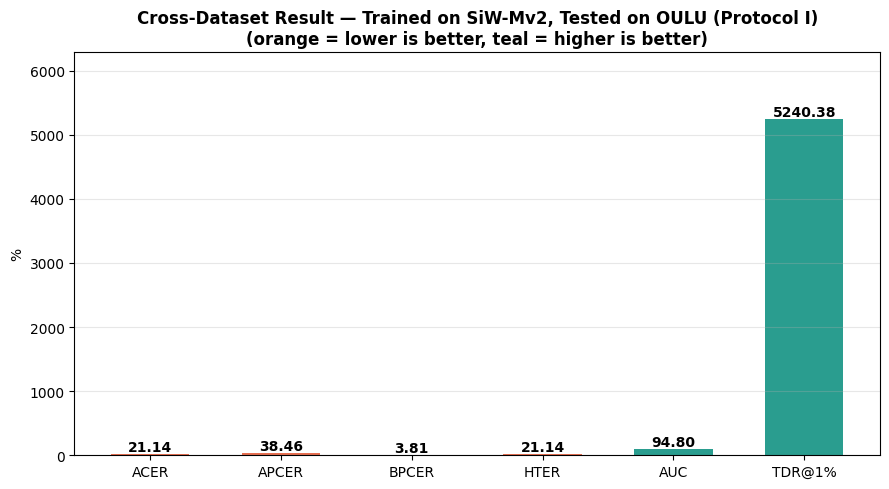

Chart saved to output_crossData/TrainSiWP1_TestOULUP1/siw_to_oulu_p1_barchart.png


In [39]:
# ============================================================================
#  Bar chart: SiW-Mv2 -> OULU cross-dataset result (all metrics)
# ============================================================================
metric_names = ['ACER', 'APCER', 'BPCER', 'HTER', 'AUC', 'TDR@1%']
metric_values = [
    opt_metrics2['ACER'] * 100,
    opt_metrics2['APCER'] * 100,
    opt_metrics2['BPCER'] * 100,
    hter2 * 100,
    opt_metrics2['AUC'] * 100,
    tdr2,
]
# lower=better metrics get one color, higher=better metrics get another
colors = ['#e76f51' if m in ['ACER', 'APCER', 'BPCER', 'HTER'] else '#2a9d8f' for m in metric_names]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(metric_names, metric_values, color=colors, width=0.6)

# value labels on top of each bar
for b in bars:
    ax.text(b.get_x() + b.get_width()/2, b.get_height(), f'{b.get_height():.2f}',
            ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_title('Cross-Dataset Result — Trained on SiW-Mv2, Tested on OULU (Protocol I)\n'
             '(orange = lower is better, teal = higher is better)', fontweight='bold')
ax.set_ylabel('%')
ax.set_ylim(0, max(metric_values) * 1.2)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()

chart_path = CROSS_DATASET_RESULT_DIR_2 / 'siw_to_oulu_p1_barchart.png'
plt.savefig(chart_path, dpi=120, bbox_inches='tight')
plt.show()

print(f'Chart saved to {chart_path}')